In [6]:
# Install research project dependencies
!pip install -q datasets transformers accelerate evaluate shap captum


In [7]:
# 1. IMPORT REQUIRED LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset loading
from datasets import load_dataset

# Classical Machine Learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# Evaluation metrics
from sklearn.metrics import (f1_score, precision_score, recall_score, hamming_loss, jaccard_score,classification_report, multilabel_confusion_matrix)

# Model utilities
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Deep Learning
import torch
import torch.nn as nn

# Transformer models
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding, set_seed,get_linear_schedule_with_warmup)

# Statistical analysis
from scipy import stats

# Explainable AI
import shap
from captum.attr import IntegratedGradients

# Other utilities
import os
import re
import json
import random
import warnings
from collections import Counter
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")


In [8]:
# 2. EXPERIMENT CONFIGURATION

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

set_seed(SEED)

# Device configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Random Seed:", SEED)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")


Random Seed: 42
Device: cuda
GPU: Tesla T4


In [9]:
# 3. CHECK ENVIRONMENT VERSIONS


import sklearn
import transformers
import datasets
import captum

versions = {
    "Python": __import__("sys").version.split()[0],
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Scikit-learn": sklearn.__version__,
    "PyTorch": torch.__version__,
    "Transformers": transformers.__version__,
    "Datasets": datasets.__version__,
    "Captum": captum.__version__
}

version_df = pd.DataFrame(
    list(versions.items()),
    columns=["Library", "Version"]
)

display(version_df)


,Library,Version
0,Python,3.13.16
1,NumPy,2.4.6
2,Pandas,2.2.3
3,Scikit-learn,1.6.1
4,PyTorch,2.14.1+cu130
5,Transformers,5.22.1
6,Datasets,4.8.5
7,Captum,0.9.0


In [10]:
# 4. LOAD GOEMOTIONS DATASET

from datasets import load_dataset

dataset = load_dataset("google-research-datasets/go_emotions", "simplified")

print("Dataset loaded successfully!")
print(dataset)



README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})


In [11]:
# 5. INSPECT DATASET SPLITS

print("Available dataset splits:")

for split in dataset.keys():
    print(split,"->",len(dataset[split]), "samples")

# Convert datasets into DataFrames

train_df = dataset["train"].to_pandas()
validation_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()
print("\nTraining shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Testing shape:", test_df.shape)
display(train_df.head())


Available dataset splits:
train -> 43410 samples
validation -> 5426 samples
test -> 5427 samples

Training shape: (43410, 3)
Validation shape: (5426, 3)
Testing shape: (5427, 3)


,text,labels,id
0,My favourite food is anything I didn't have to...,[27],eebbqej
1,"Now if he does off himself, everyone will thin...",[27],ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj
3,To make her feel threatened,[14],ed7ypvh
4,Dirty Southern Wankers,[3],ed0bdzj


In [12]:
# 6. DATASET STRUCTURE

print("Training columns:")
print(train_df.columns.tolist())

print("\nDataset information:")
print(train_df.info())

print("\nFirst sample:")
print(train_df.iloc[0])


Training columns:
['text', 'labels', 'id']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43410 entries, 0 to 43409
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    43410 non-null  object
 1   labels  43410 non-null  object
 2   id      43410 non-null  object
dtypes: object(3)
memory usage: 1017.6+ KB
None

First sample:
text      My favourite food is anything I didn't have to...
labels                                                 [27]
id                                                  eebbqej
Name: 0, dtype: object


In [13]:
# 7. EXTRACT EMOTION LABELS

label_names = (dataset["train"].features["labels"].feature.names)
print("Total emotion categories:", len(label_names))

for index, emotion in enumerate(label_names):
    print(f"{index}: {emotion}")

Total emotion categories: 28
0: admiration
1: amusement
2: anger
3: annoyance
4: approval
5: caring
6: confusion
7: curiosity
8: desire
9: disappointment
10: disapproval
11: disgust
12: embarrassment
13: excitement
14: fear
15: gratitude
16: grief
17: joy
18: love
19: nervousness
20: optimism
21: pride
22: realization
23: relief
24: remorse
25: sadness
26: surprise
27: neutral


In [14]:
# 8. MAP LABEL IDS TO EMOTION NAMES
def convert_labels(label_ids):
    return [
        label_names[label_id]
        for label_id in label_ids
    ]

train_df["emotion_names"] = train_df["labels"].apply(convert_labels)
validation_df["emotion_names"] = validation_df["labels"].apply(convert_labels)
test_df["emotion_names"] = test_df["labels"].apply(convert_labels)

display(train_df[["text", "labels", "emotion_names"]].head(10))

,text,labels,emotion_names
0,My favourite food is anything I didn't have to...,[27],[neutral]
1,"Now if he does off himself, everyone will thin...",[27],[neutral]
2,WHY THE FUCK IS BAYLESS ISOING,[2],[anger]
3,To make her feel threatened,[14],[fear]
4,Dirty Southern Wankers,[3],[annoyance]
5,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,[26],[surprise]
6,Yes I heard abt the f bombs! That has to be wh...,[15],[gratitude]
7,We need more boards and to create a bit more s...,"[8, 20]","[desire, optimism]"
8,Damn youtube and outrage drama is super lucrat...,[0],[admiration]
9,It might be linked to the trust factor of your...,[27],[neutral]


In [15]:
# 9. MISSING VALUES ANALYSIS

print("Missing values in training dataset:")
display(train_df.isnull().sum())

print("\nMissing values in validation dataset:")
display(validation_df.isnull().sum())

print("\nMissing values in test dataset:")
display(test_df.isnull().sum())

Missing values in training dataset:


,0
text,0
labels,0
id,0
emotion_names,0



Missing values in validation dataset:


,0
text,0
labels,0
id,0
emotion_names,0



Missing values in test dataset:


,0
text,0
labels,0
id,0
emotion_names,0


In [16]:
# 10. DUPLICATE RECORD ANALYSIS

print("Training duplicates:", train_df["text"].duplicated().sum())
print("Validation duplicates:",validation_df["text"].duplicated().sum())
print("Test duplicates:", test_df["text"].duplicated().sum())


# Check duplicate text across official splits
train_texts = set(train_df["text"])
validation_texts = set(validation_df["text"])
test_texts = set(test_df["text"])

print("\nTrain-validation overlap:", len(train_texts & validation_texts))
print("Train-test overlap:", len(train_texts & test_texts))
print("Validation-test overlap:", len(validation_texts & test_texts))


Training duplicates: 183
Validation duplicates: 3
Test duplicates: 6

Train-validation overlap: 41
Train-test overlap: 32
Validation-test overlap: 10


In [17]:
# 11. EMOTION FREQUENCY DISTRIBUTION
label_counts = np.zeros(len(label_names), dtype=int)

for labels in train_df["labels"]:
    for label in labels:
        label_counts[label] += 1

emotion_distribution = pd.DataFrame({"Emotion": label_names, "Frequency": label_counts})
emotion_distribution = emotion_distribution.sort_values(by="Frequency", ascending=False)

display(emotion_distribution)

,Emotion,Frequency
27,neutral,14219
0,admiration,4130
4,approval,2939
15,gratitude,2662
3,annoyance,2470
1,amusement,2328
7,curiosity,2191
18,love,2086
10,disapproval,2022
20,optimism,1581


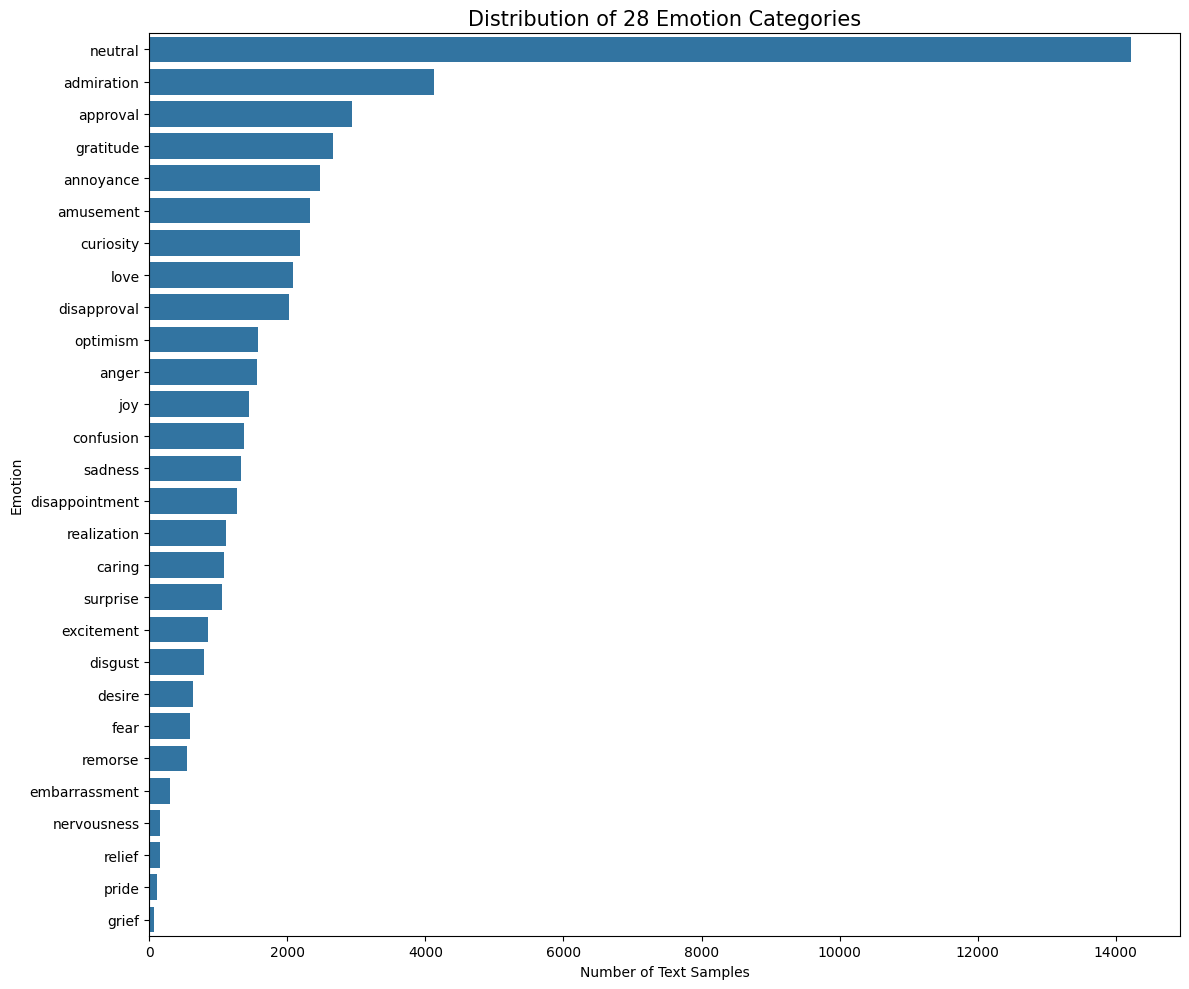

In [18]:
# 12. EMOTION DISTRIBUTION VISUALIZATION

plt.figure(figsize=(12, 10))
sns.barplot(data=emotion_distribution, x="Frequency", y="Emotion")
plt.title("Distribution of 28 Emotion Categories", fontsize=15)

plt.xlabel("Number of Text Samples")
plt.ylabel("Emotion")

plt.tight_layout()
plt.show()

In [19]:
# 13. TOP AND BOTTOM EMOTIONS

print("TOP 10 MOST FREQUENT EMOTIONS")
display(emotion_distribution.head(10))

print("\n10 LEAST FREQUENT EMOTIONS")
display(emotion_distribution.tail(10))

TOP 10 MOST FREQUENT EMOTIONS


,Emotion,Frequency
27,neutral,14219
0,admiration,4130
4,approval,2939
15,gratitude,2662
3,annoyance,2470
1,amusement,2328
7,curiosity,2191
18,love,2086
10,disapproval,2022
20,optimism,1581



10 LEAST FREQUENT EMOTIONS


,Emotion,Frequency
13,excitement,853
11,disgust,793
8,desire,641
14,fear,596
24,remorse,545
12,embarrassment,303
19,nervousness,164
23,relief,153
21,pride,111
16,grief,77


In [20]:
# 14. MULTI-LABEL DISTRIBUTION

train_df["number_of_labels"] = train_df["labels"].apply(len)
print("Average labels per sample:", train_df["number_of_labels"].mean())
print("Maximum labels per sample:", train_df["number_of_labels"].max())


print("Minimum labels per sample:", train_df["number_of_labels"].min())
print("\nNumber of labels per sample:")

display(train_df["number_of_labels"].value_counts().sort_index())

Average labels per sample: 1.1772172310527529
Maximum labels per sample: 5
Minimum labels per sample: 1

Number of labels per sample:


,count
number_of_labels,
1,36308
2,6541
3,532
4,28
5,1


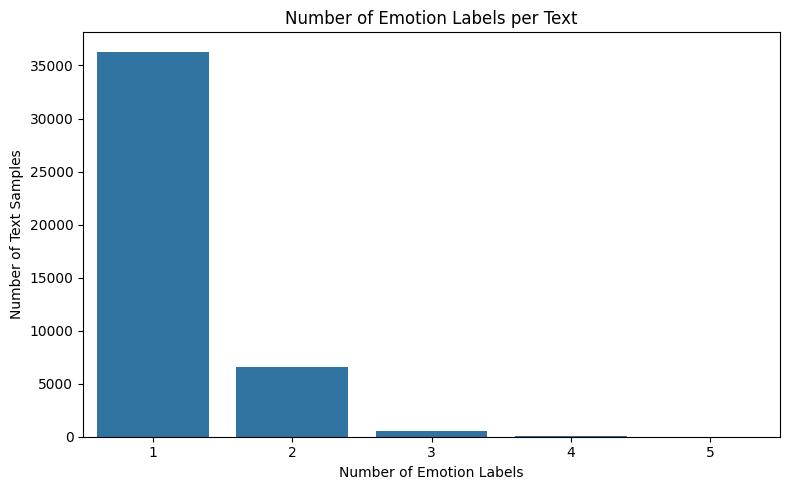

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(data=train_df, x="number_of_labels")

plt.title("Number of Emotion Labels per Text")
plt.xlabel("Number of Emotion Labels")
plt.ylabel("Number of Text Samples")

plt.tight_layout()
plt.show()

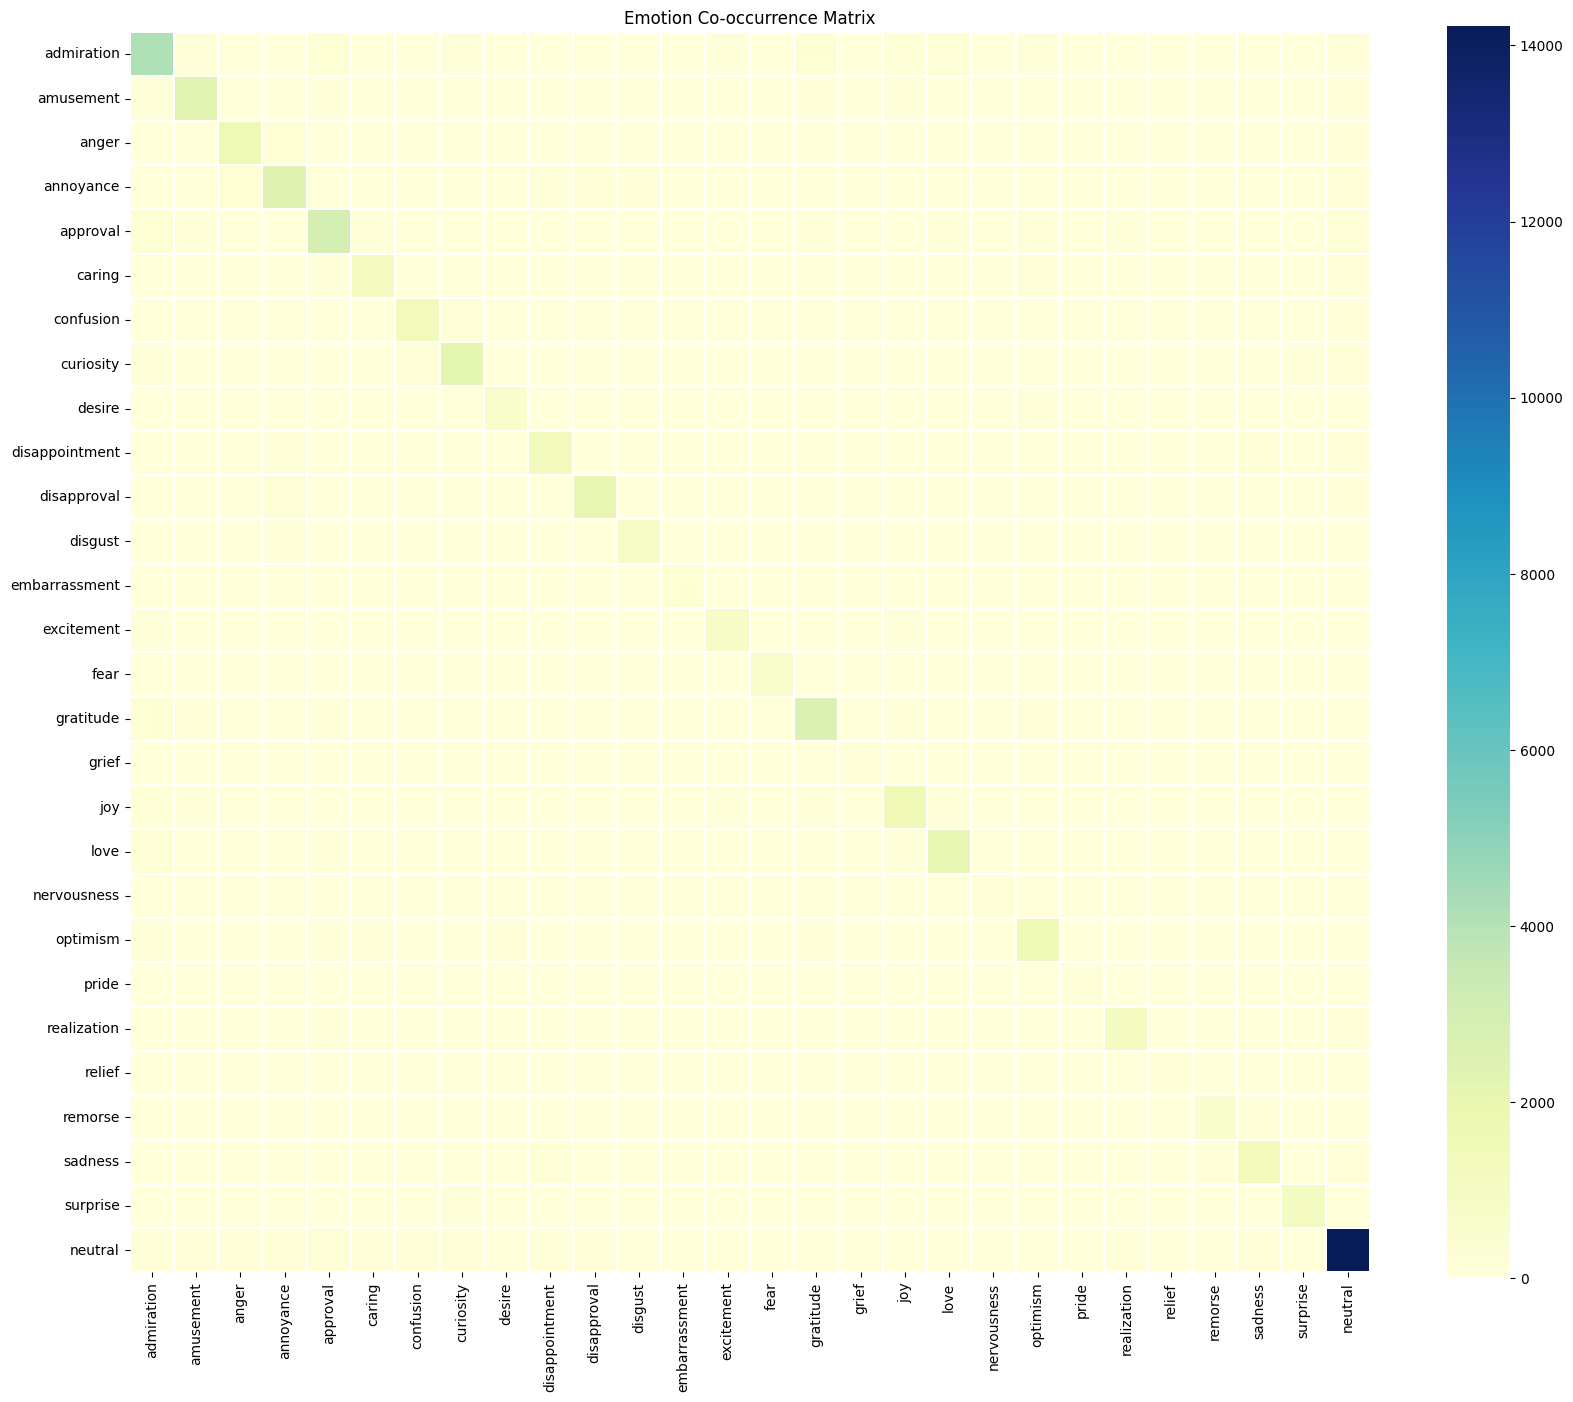

In [22]:
# 15. EMOTION CO-OCCURRENCE MATRIX
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer(classes=range(len(label_names)))
Y_train = mlb.fit_transform(train_df["labels"])

co_occurrence = pd.DataFrame(Y_train.T @ Y_train,index=label_names, columns=label_names)
plt.figure(figsize=(17, 14))

sns.heatmap(co_occurrence, cmap="YlGnBu", square=True, linewidths=0.1)
plt.title("Emotion Co-occurrence Matrix")
plt.tight_layout()
plt.show()

In [23]:
# 16. SAMPLE TEXT ANALYSIS

for i in range(10):

    print(f"\nSample {i+1}")
    print("-" * 50)

    print("Text:", train_df.iloc[i]["text"])
    print("Emotions:", train_df.iloc[i]["emotion_names"])


Sample 1
--------------------------------------------------
Text: My favourite food is anything I didn't have to cook myself.
Emotions: ['neutral']

Sample 2
--------------------------------------------------
Text: Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead
Emotions: ['neutral']

Sample 3
--------------------------------------------------
Text: WHY THE FUCK IS BAYLESS ISOING
Emotions: ['anger']

Sample 4
--------------------------------------------------
Text: To make her feel threatened
Emotions: ['fear']

Sample 5
--------------------------------------------------
Text: Dirty Southern Wankers
Emotions: ['annoyance']

Sample 6
--------------------------------------------------
Text: OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe PlAyOfFs! Dumbass Broncos fans circa December 2015.
Emotions: ['surprise']

Sample 7
--------------------------------------------------
Text: Yes I heard abt the f bombs! That has to be why

In [24]:
# 17. EXPORT EDA RESULTS

import os

os.makedirs("research_outputs/eda", exist_ok=True)

emotion_distribution.to_csv("research_outputs/eda/emotion_distribution.csv",  index=False)
co_occurrence.to_csv("research_outputs/eda/emotion_cooccurrence.csv")
train_df["number_of_labels"].value_counts().sort_index().to_csv("research_outputs/eda/multilabel_distribution.csv")

print("EDA results exported successfully!")

EDA results exported successfully!


In [25]:
import shutil
from google.colab import files

shutil.make_archive("GoEmotions_EDA_Results", "zip", "research_outputs/eda")

files.download("GoEmotions_EDA_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# 18. Prepare training, validation and test data

X_train = train_df["text"].astype(str)
X_val = validation_df["text"].astype(str)
X_test = test_df["text"].astype(str)

# Convert labels into binary matrices
Y_train = mlb.transform(train_df["labels"])
Y_val = mlb.transform(validation_df["labels"])
Y_test = mlb.transform(test_df["labels"])

print("Training:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Testing:", X_test.shape, Y_test.shape)

Training: (43410,) (43410, 28)
Validation: (5426,) (5426, 28)
Testing: (5427,) (5427, 28)


In [27]:
# 19. Verify multi-label encoding

encoded_df = pd.DataFrame(Y_train[:10], columns=label_names)
display(encoded_df)

print("Total positive labels:", Y_train.sum())
print("Average labels per sample:", Y_train.sum(axis=1).mean())

,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,desire,disappointment,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,1,0,...,0,0,1,0,0,0,0,0,0,0
8,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


Total positive labels: 51103
Average labels per sample: 1.1772172310527529


Average words: 12.840175074867542
Minimum words: 1
Maximum words: 33
Median words: 12.0


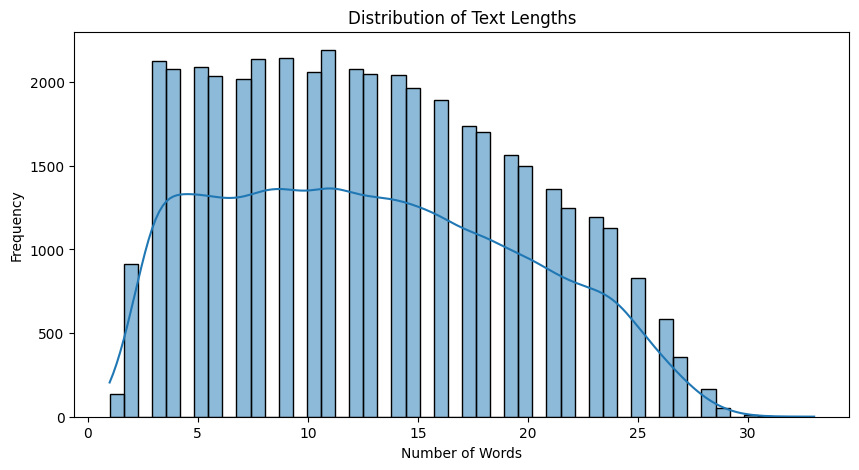

In [28]:
# 20. Analyse Text length
text_lengths = X_train.str.split().str.len()

print("Average words:", text_lengths.mean())
print("Minimum words:", text_lengths.min())
print("Maximum words:", text_lengths.max())
print("Median words:", text_lengths.median())

plt.figure(figsize=(10, 5))
sns.histplot(text_lengths, bins=50, kde=True)

plt.title("Distribution of Text Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [29]:
# 21. Generate TF-IDF features
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True, strip_accents="unicode")
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training:", X_train_tfidf.shape)
print("Validation:", X_val_tfidf.shape)
print("Testing:", X_test_tfidf.shape)

Training: (43410, 50000)
Validation: (5426, 50000)
Testing: (5427, 50000)


In [30]:
# 22. Export preprocessing objects
import os
import joblib

os.makedirs("research_outputs/preprocessing", exist_ok=True)
joblib.dump(tfidf,"research_outputs/preprocessing/tfidf_vectorizer.pkl")

joblib.dump(mlb, "research_outputs/preprocessing/multilabel_binarizer.pkl")
print("Preprocessing objects saved successfully!")

Preprocessing objects saved successfully!


In [31]:
#23. Created an evaluation function
def evaluate_model(y_true, y_pred, model_name):

    results = {
        "Model": model_name,
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Micro F1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Micro Precision": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "Micro Recall": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "Hamming Loss": hamming_loss(y_true, y_pred),
        "Jaccard Score": jaccard_score(y_true, y_pred, average="samples", zero_division=0)
    }

    return results

In [32]:
#24. Training of Logistic regression
lg_model = OneVsRestClassifier(LogisticRegression(max_iter=1000, solver="liblinear",random_state=42))
lg_model.fit(X_train_tfidf, Y_train)
lg_val_scores = lg_model.predict_proba(X_val_tfidf)
lg_val_pred = (lg_val_scores >= 0.5).astype(int)
print("Logistic Regression training completed!")

Logistic Regression training completed!


In [33]:
#25. Training of Linear SVM
from scipy.special import expit

svm_model = OneVsRestClassifier(LinearSVC(C=1.0, random_state=42, max_iter=3000))
svm_model.fit(X_train_tfidf, Y_train)

# Convert SVM raw decision boundaries into probabilities [0, 1] using Sigmoid
svm_val_scores = expit(svm_model.decision_function(X_val_tfidf))
svm_val_pred = (svm_val_scores >= 0.5).astype(int)
print("Linear SVM training completed!")

Linear SVM training completed!


In [34]:
#26. Training of Multinomial Naive Bayes
nb_model = OneVsRestClassifier(MultinomialNB(alpha=1.0))
nb_model.fit(X_train_tfidf, Y_train)
nb_val_scores = nb_model.predict_proba(X_val_tfidf)
nb_val_pred = (nb_val_scores >= 0.5).astype(int)
print("Naive Bayes training completed!")

Naive Bayes training completed!


In [35]:
#27. Comparing of validation performance
results = []

results.append(evaluate_model(Y_val, lg_val_pred, "Logistic Regression"))
results.append(evaluate_model(Y_val, svm_val_pred, "Linear SVM"))
results.append(evaluate_model(Y_val, nb_val_pred, "Multinomial Naive Bayes"))
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,Logistic Regression,0.2021,0.3789,0.5439,0.1442,0.7225,0.2567,0.0354,0.2722
1,Linear SVM,0.3289,0.4709,0.6023,0.2524,0.6577,0.3668,0.0346,0.3750
2,Multinomial Naive Bayes,0.0210,0.0645,0.1221,0.0122,0.8327,0.0335,0.0409,0.0370


**Interpretations**

Logistic Regression - Strong precision

It has precision value 0.7225, higher than Linear SVM. However, its recall is lower, means it misses more actual emotion labels.

Multinomial Naive Bayes - Weak performance

It has higher precision at 0.8327, but recall is only 0.0335. This suggests that it predicts very few positive emotion labels, and the predictions it does make are relatively selective.

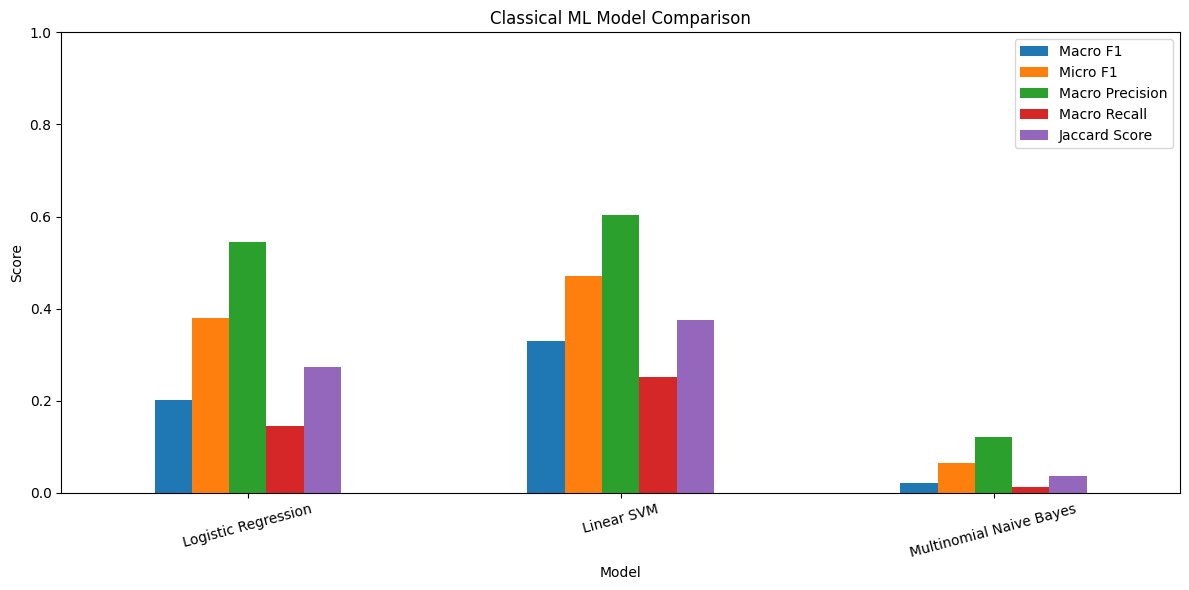

In [36]:
# 28. visualization of model performances
metrics = ["Macro F1", "Micro F1", "Macro Precision", "Macro Recall", "Jaccard Score"]
results_df.set_index("Model")[metrics].plot(kind="bar", figsize=(12, 6))
plt.title("Classical ML Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [37]:
# 29. save files

import os
os.makedirs("research_outputs/classical_models", exist_ok=True)
results_df.to_csv("research_outputs/classical_models/validation_results.csv",index=False)
print("Validation results saved!")

Validation results saved!


In [38]:
# 30.  Collect validation scores from all three models

validation_scores = {"Logistic Regression": lg_val_scores, "Linear SVM": svm_val_scores, "Multinomial Naive Bayes": nb_val_scores}
print("Validation scores prepared.")

for name, scores in validation_scores.items():
    print(name, scores.shape)

Validation scores prepared.
Logistic Regression (5426, 28)
Linear SVM (5426, 28)
Multinomial Naive Bayes (5426, 28)


In [39]:
def optimize_thresholds(y_true, y_scores):
    thresholds = np.zeros(y_true.shape[1])

    # Search finer steps from 0.02 to 0.90
    threshold_values = np.arange(0.02, 0.91, 0.02)
    for label in range(y_true.shape[1]):
        best_threshold = 0.5
        best_f1 = 0.0
        for threshold in threshold_values:
            predictions = (y_scores[:, label] >= threshold).astype(int)
            score = f1_score(y_true[:, label], predictions, zero_division=0)

            if score > best_f1:
                best_f1 = score
                best_threshold = threshold

        # Default fallback of 0.20 for extremely rare classes
        thresholds[label] = best_threshold if best_f1 > 0 else 0.20

    return thresholds

In [40]:
optimized_thresholds = {}
for name, scores in validation_scores.items():
    thresholds = optimize_thresholds(Y_val, scores)
    optimized_thresholds[name] = thresholds

    print(f"\n{name}")
    print("Thresholds:", np.round(thresholds, 2))


Logistic Regression
Thresholds: [0.2  0.08 0.1  0.1  0.14 0.08 0.12 0.2  0.12 0.06 0.1  0.06 0.02 0.06
 0.04 0.24 0.2  0.1  0.16 0.02 0.12 0.02 0.08 0.04 0.06 0.12 0.08 0.34]

Linear SVM
Thresholds: [0.44 0.42 0.38 0.36 0.38 0.36 0.4  0.42 0.4  0.38 0.36 0.38 0.34 0.36
 0.38 0.44 0.34 0.42 0.42 0.38 0.42 0.36 0.44 0.38 0.38 0.42 0.38 0.38]

Multinomial Naive Bayes
Thresholds: [0.08 0.04 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.2  0.02
 0.02 0.08 0.2  0.02 0.04 0.2  0.02 0.2  0.02 0.2  0.02 0.02 0.02 0.2 ]


In [41]:
optimized_val_predictions = {}

for name, scores in validation_scores.items():
    thresholds = optimized_thresholds[name]
    predictions = (scores >= thresholds.reshape(1, -1)).astype(int)
    optimized_val_predictions[name] = predictions

    print(name, predictions.shape)

Logistic Regression (5426, 28)
Linear SVM (5426, 28)
Multinomial Naive Bayes (5426, 28)


In [42]:
comparison = []

default_predictions = {"Logistic Regression": lg_val_pred, "Linear SVM": svm_val_pred, "Multinomial Naive Bayes": nb_val_pred}
for name in validation_scores:
    default_result = evaluate_model(Y_val, default_predictions[name], name + " - Default")
    optimized_result = evaluate_model(Y_val, optimized_val_predictions[name], name + " - Optimized")

    comparison.extend([default_result, optimized_result])
threshold_comparison_df = pd.DataFrame(comparison)
display(threshold_comparison_df.round(4))

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,Logistic Regression - Default,0.2021,0.3789,0.5439,0.1442,0.7225,0.2567,0.0354,0.2722
1,Logistic Regression - Optimized,0.4627,0.5484,0.4708,0.4848,0.4998,0.6074,0.0420,0.5013
2,Linear SVM - Default,0.3289,0.4709,0.6023,0.2524,0.6577,0.3668,0.0346,0.3750
3,Linear SVM - Optimized,0.4750,0.5284,0.4873,0.4869,0.4766,0.5929,0.0444,0.4723
4,Multinomial Naive Bayes - Default,0.0210,0.0645,0.1221,0.0122,0.8327,0.0335,0.0409,0.0370
5,Multinomial Naive Bayes - Optimized,0.1614,0.3576,0.2117,0.1515,0.3405,0.3765,0.0568,0.3168


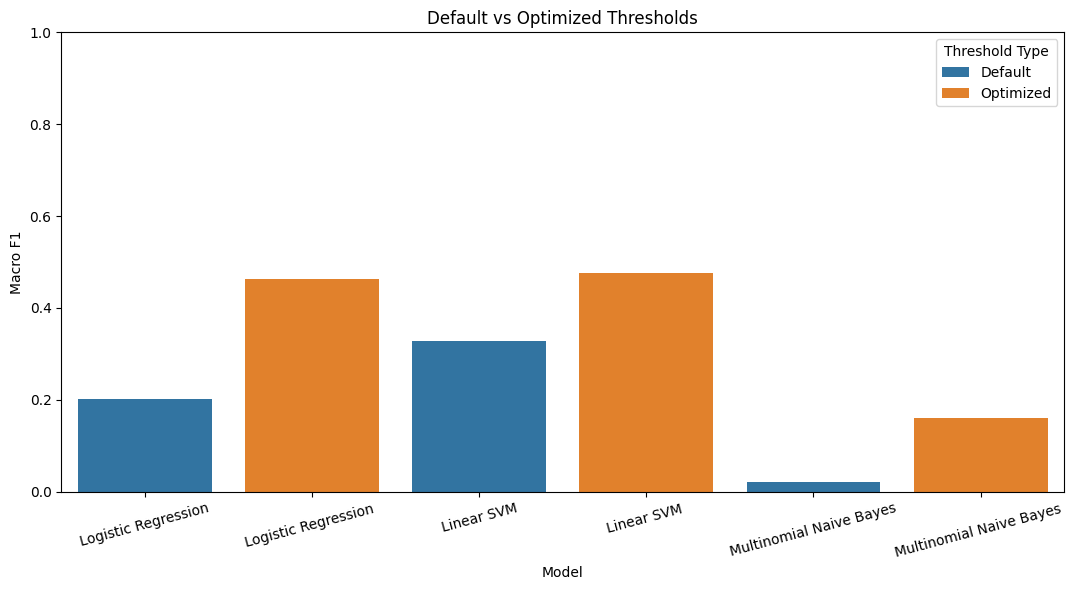

In [43]:
plot_df = threshold_comparison_df[["Model", "Macro F1"]].copy()
plot_df["Threshold Type"] = plot_df["Model"].apply(lambda x: "Optimized" if "Optimized" in x else "Default")
plot_df["Model"] = plot_df["Model"].str.replace(" - Default", "", regex=False).str.replace("- Optimized", "", regex=False)
plt.figure(figsize=(11, 6))

sns.barplot(data=plot_df, x="Model", y="Macro F1", hue="Threshold Type")

plt.title("Default vs Optimized Thresholds")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [44]:
import os
import json

os.makedirs("research_outputs/classical_models", exist_ok=True)
threshold_comparison_df.to_csv("research_outputs/classical_models/threshold_comparison.csv", index=False)

threshold_data = {name: thresholds.tolist()
for name, thresholds in optimized_thresholds.items()}
with open("research_outputs/classical_models/optimized_thresholds.json", "w" ) as f: json.dump(threshold_data, f, indent=4)
print("Threshold optimization results saved!")

Threshold optimization results saved!


In [45]:
# Final test predictions using optimized Logistic Regression & Linear SVM thresholds

# 1. Logistic Regression
lg_test_scores = lg_model.predict_proba(X_test_tfidf)
lg_test_thresholds = optimized_thresholds["Logistic Regression"]
lg_test_pred = (lg_test_scores >= lg_test_thresholds.reshape(1, -1)).astype(int)
final_test_results = evaluate_model(Y_test, lg_test_pred, "Optimized Logistic Regression")

# 2. Linear SVM (using expit probabilities)
svm_test_scores = expit(svm_model.decision_function(X_test_tfidf))
svm_test_thresholds = optimized_thresholds["Linear SVM"]
svm_test_pred = (svm_test_scores >= svm_test_thresholds.reshape(1, -1)).astype(int)
final_svm_results = evaluate_model(Y_test, svm_test_pred, "Optimized Linear SVM")

# Display both
display(pd.DataFrame([final_test_results, final_svm_results]).round(4))

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,Optimized Logistic Regression,0.4408,0.5367,0.4490,0.4651,0.4845,0.6015,0.0432,0.4854
1,Optimized Linear SVM,0.4502,0.5236,0.4614,0.4658,0.4673,0.5952,0.0451,0.4714


In [46]:
final_test_df = pd.DataFrame([final_test_results])

final_test_df.to_csv("research_outputs/classical_models/" "final_logistic_regression_test_results.csv", index=False)
print("Final test evaluation saved!")

Final test evaluation saved!


In [47]:
import gc
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))
print("Labels:", Y_train.shape[1])

GPU available: True
GPU: Tesla T4
Train: 43410
Validation: 5426
Test: 5427
Labels: 28


In [48]:
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from tqdm.auto import tqdm

In [49]:
class EmotionDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = list(texts)
        self.labels = torch.tensor(labels,dtype=torch.float32)
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        return { "text": self.texts[index], "labels": self.labels[index]}

In [50]:
def create_collate_fn(tokenizer, max_length=128):
    def collate_fn(batch):
        texts = [item["text"] for item in batch]
        labels = torch.stack([item["labels"] for item in batch])
        encoding = tokenizer(texts,padding=True,truncation=True,max_length=max_length,return_tensors="pt")
        encoding["labels"] = labels
        return encoding
    return collate_fn

In [51]:
def train_transformer(model_name, run_name, epochs=3, batch_size=16, gradient_accumulation_steps=1, max_length=128):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=28, problem_type="multi_label_classification")
    model.to(device)

    # Class weights for imbalanced emotions
    pos_counts = torch.tensor(Y_train.sum(axis=0), dtype=torch.float32)
    neg_counts = len(Y_train) - pos_counts
    pos_weight = torch.clamp(neg_counts / (pos_counts + 1e-5), min=1.0, max=10.0).to(device)

    train_dataset = EmotionDataset(X_train, Y_train)
    val_dataset = EmotionDataset(X_val, Y_val)

    collate_fn = create_collate_fn(tokenizer, max_length)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

    optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)

    total_steps = (len(train_loader) // gradient_accumulation_steps) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)

    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    best_macro_f1 = -1
    history = []

    os.makedirs(f"research_outputs/{run_name}", exist_ok=True)
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        optimizer.zero_grad(set_to_none=True)
        progress = tqdm(train_loader, desc=f"{run_name} Epoch {epoch + 1}")

        for step, batch in enumerate(progress):
            labels = batch.pop("labels").to(device)
            inputs = {key: value.to(device) for key, value in batch.items()}

            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
                outputs = model(**inputs)
                loss = torch.nn.functional.binary_cross_entropy_with_logits(outputs.logits, labels, pos_weight=pos_weight)
                loss = loss / gradient_accumulation_steps

            scaler.scale(loss).backward()

            if (step + 1) % gradient_accumulation_steps == 0 or (step + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()

            total_loss += loss.item() * gradient_accumulation_steps
            progress.set_postfix(loss=loss.item() * gradient_accumulation_steps)

        # Validation
        model.eval()
        all_scores = []
        with torch.no_grad():
            for batch in val_loader:
                batch.pop("labels")
                inputs = {key: value.to(device) for key, value in batch.items()}
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
                    logits = model(**inputs).logits
                probabilities = torch.sigmoid(logits.float())
                all_scores.append(probabilities.cpu().numpy())

        val_scores = np.vstack(all_scores)
        val_predictions = (val_scores >= 0.5).astype(int)
        macro_f1 = f1_score(Y_val, val_predictions, average="macro", zero_division=0)
        avg_loss = total_loss / len(train_loader)
        history.append({"Epoch": epoch + 1, "Training Loss": avg_loss, "Validation Macro F1": macro_f1})
        print(f"Epoch {epoch + 1}: Loss={avg_loss:.4f}, Validation Macro F1={macro_f1:.4f}")

        if macro_f1 > best_macro_f1:
            best_macro_f1 = macro_f1
            model.save_pretrained(f"research_outputs/{run_name}/best_model")
            tokenizer.save_pretrained(f"research_outputs/{run_name}/best_model")
            np.save(f"research_outputs/{run_name}/validation_scores.npy", val_scores)

    history_df = pd.DataFrame(history)
    history_df.to_csv(f"research_outputs/{run_name}/training_history.csv", index=False)
    print("Best validation Macro F1:", best_macro_f1)
    return history_df, best_macro_f1

In [52]:
distil_history, distil_best_f1 = train_transformer(model_name="distilbert-base-uncased", run_name="distilbert",epochs=2, batch_size=16, max_length=128)
display(distil_history)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

Epoch 2: Loss=0.2956, Validation Macro F1=0.4690


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best validation Macro F1: 0.469018984921879


,Epoch,Training Loss,Validation Macro F1
0,1,0.439570,0.430350
1,2,0.295591,0.469019


In [53]:
# batch_size=8 with gradient_accumulation_steps=2 gives effective batch size 16 to match DistilBERT

bert_history, bert_best_f1 = train_transformer(model_name="bert-base-uncased", run_name="bert", epochs=3, batch_size=8, gradient_accumulation_steps=2, max_length=128)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (8 outputs left out)

bert Epoch 3:   0%|          | 0/5427 [00:00<?, ?it/s]

Epoch 3: Loss=0.2462, Validation Macro F1=0.4724


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best validation Macro F1: 0.47242579346359115


In [54]:
transformer_comparison = pd.DataFrame([{"Model": "DistilBERT","Best Validation Macro F1": distil_best_f1}, {"Model": "BERT","Best Validation Macro F1": bert_best_f1}])
display(transformer_comparison.round(4))

,Model,Best Validation Macro F1
0,DistilBERT,0.4690
1,BERT,0.4724


In [55]:
distil_val_scores = np.load("research_outputs/distilbert/validation_scores.npy")
bert_val_scores = np.load("research_outputs/bert/validation_scores.npy")
distil_thresholds = optimize_thresholds(Y_val, distil_val_scores)
bert_thresholds = optimize_thresholds(Y_val, bert_val_scores)

In [56]:
transformer_threshold_results = []

for name, scores, thresholds in [("DistilBERT", distil_val_scores, distil_thresholds), ("BERT", bert_val_scores, bert_thresholds)]:
    predictions = (scores >= thresholds.reshape(1, -1)).astype(int)
    transformer_threshold_results.append(evaluate_model(Y_val, predictions,name + " Optimized"))
transformer_threshold_df = pd.DataFrame(transformer_threshold_results)
display(transformer_threshold_df.round(4))

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,DistilBERT Optimized,0.5303,0.6078,0.5225,0.5571,0.5530,0.6746,0.0366,0.5691
1,BERT Optimized,0.5514,0.6083,0.5439,0.5759,0.5598,0.6660,0.0360,0.5715


In [57]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
selected_model = AutoModelForSequenceClassification.from_pretrained("research_outputs/distilbert/best_model").to(device)
selected_tokenizer = AutoTokenizer.from_pretrained("research_outputs/distilbert/best_model")
test_dataset = EmotionDataset(X_test, Y_test)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, collate_fn=create_collate_fn(selected_tokenizer, 128))

selected_model.eval()
test_scores = []
with torch.no_grad():
    for batch in tqdm(test_loader):
        batch.pop("labels")
        inputs = {
            key: value.to(device)
            for key, value in batch.items()
        }
        logits = selected_model(**inputs).logits
        test_scores.append(
            torch.sigmoid(logits.float()).cpu().numpy()
        )

test_scores = np.vstack(test_scores)

transformer_test_predictions = (test_scores >= distil_thresholds.reshape(1, -1)).astype(int)
transformer_test_results = evaluate_model(Y_test, transformer_test_predictions, "DistilBERT Optimized")
display(pd.DataFrame([transformer_test_results]).round(4))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  0%|          | 0/340 [00:00<?, ?it/s]

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,DistilBERT Optimized,0.4959,0.5951,0.4919,0.5377,0.5394,0.6636,0.0376,0.5542


In [58]:
bert_val_predictions = (bert_val_scores >= bert_thresholds.reshape(1, -1)).astype(int)
bert_val_results = evaluate_model(Y_val,bert_val_predictions, "BERT Optimized")
display(pd.DataFrame([bert_val_results]).round(4))

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,BERT Optimized,0.5514,0.6083,0.5439,0.5759,0.5598,0.666,0.036,0.5715


In [59]:

# Load the already trained BERT model

bert_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model = AutoModelForSequenceClassification.from_pretrained("research_outputs/bert/best_model").to(bert_device)
bert_tokenizer = AutoTokenizer.from_pretrained("research_outputs/bert/best_model")

bert_model.eval()

print("BERT model loaded successfully!")
print("BERT tokenizer loaded successfully!")
print("Device:", bert_device)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BERT model loaded successfully!
BERT tokenizer loaded successfully!
Device: cuda


In [60]:
bert_model.eval()

bert_test_dataset = EmotionDataset(X_test, Y_test)
bert_test_loader = DataLoader(bert_test_dataset,batch_size=8, shuffle=False, collate_fn=create_collate_fn(bert_tokenizer, 128))

bert_test_scores = []
with torch.no_grad():
    for batch in tqdm(bert_test_loader):
        batch.pop("labels")
        inputs = {
            key: value.to(bert_device)
            for key, value in batch.items()
        }

        outputs = bert_model(**inputs)
        probabilities = torch.sigmoid(outputs.logits.float())
        bert_test_scores.append(probabilities.cpu().numpy())

bert_test_scores = np.vstack(bert_test_scores)
bert_test_predictions = (bert_test_scores >= bert_thresholds.reshape(1, -1)).astype(int)

bert_test_results = evaluate_model(Y_test, bert_test_predictions,"BERT Optimized")

display(pd.DataFrame([bert_test_results]).round(4))

  0%|          | 0/679 [00:00<?, ?it/s]

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,BERT Optimized,0.5177,0.5968,0.5057,0.5563,0.5444,0.6605,0.0372,0.5582


In [61]:
final_comparison = pd.DataFrame([final_test_results, final_svm_results, transformer_test_results, bert_test_results])
display(final_comparison.round(4))

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,Optimized Logistic Regression,0.4408,0.5367,0.4490,0.4651,0.4845,0.6015,0.0432,0.4854
1,Optimized Linear SVM,0.4502,0.5236,0.4614,0.4658,0.4673,0.5952,0.0451,0.4714
2,DistilBERT Optimized,0.4959,0.5951,0.4919,0.5377,0.5394,0.6636,0.0376,0.5542
3,BERT Optimized,0.5177,0.5968,0.5057,0.5563,0.5444,0.6605,0.0372,0.5582


In [62]:
os.makedirs("research_outputs/final_results", exist_ok=True)
final_comparison.to_csv("research_outputs/final_results/final_model_comparison.csv", index=False)
print("Final results saved successfully!")

Final results saved successfully!


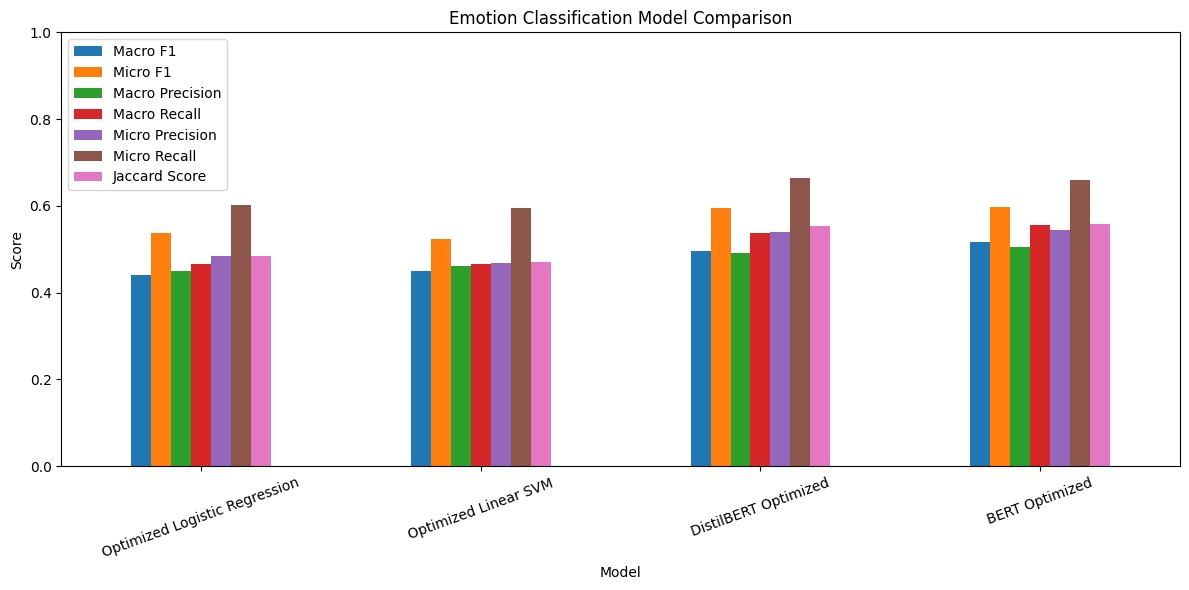

In [64]:
metrics = ["Macro F1", "Micro F1", "Macro Precision",	"Macro Recall",	"Micro Precision",	"Micro Recall", "Jaccard Score"]
final_comparison.set_index("Model")[metrics].plot(kind="bar",figsize=(12, 6))

plt.title("Emotion Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [69]:
random.seed(42)

# 1. Remove words
def delete_words(text):
    words = text.split()
    if len(words) <= 2:
        return text
    new_words = [word for word in words if random.random() > 0.10]
    return " ".join(new_words) if len(new_words) > 0 else text

# 2. Repeat words
def repeat_words(text):
    words = text.split()
    new_words = []
    for word in words:
        new_words.append(word)
        if random.random() < 0.10:
            new_words.append(word)
    return " ".join(new_words)

# 3. Delete characters
def delete_characters(text):
    words = text.split()
    new_words = []
    for word in words:
        if len(word) > 3 and random.random() < 0.10:
            position = random.randint(1, len(word) - 2)
            word = word[:position] + word[position + 1:]
        new_words.append(word)
    return " ".join(new_words)

# 4. Swap characters
def swap_characters(text):
    words = text.split()
    new_words = []
    for word in words:
        if len(word) > 3 and random.random() < 0.10:
            position = random.randint(1, len(word) - 2)
            letters = list(word)
            letters[position], letters[position + 1] = letters[position + 1], letters[position]
            word = "".join(letters)
        new_words.append(word)
    return " ".join(new_words)

print("All text modification functions are ready!")

All text modification functions are ready!


In [70]:
# Keep original test data unchanged
clean_texts = X_test.tolist()

# Create modified versions
word_deleted = [delete_words(t) for t in clean_texts]
word_repeated = [repeat_words(t) for t in clean_texts]
character_deleted = [delete_characters(t) for t in clean_texts]
character_swapped = [swap_characters(t) for t in clean_texts]


print("Clean samples:", len(clean_texts))
print("Word deletion:", len(word_deleted))
print("Word repetition:", len(word_repeated))
print("Character deletion:", len(character_deleted))
print("Character swapping:", len(character_swapped))

Clean samples: 5427
Word deletion: 5427
Word repetition: 5427
Character deletion: 5427
Character swapping: 5427


In [71]:
for i in range(5):
    print("\nOriginal:", clean_texts[i])
    print("Word deleted:", word_deleted[i])
    print("Word repeated:", word_repeated[i])
    print("Character deleted:", character_deleted[i])
    print("Character swapped:", character_swapped[i])
    print("-" * 60)


Original: I’m really sorry about your situation :( Although I love the names Sapphira, Cirilla, and Scarlett!
Word deleted: I’m sorry about your situation :( I the names Cirilla, and Scarlett!
Word repeated: I’m really sorry about your situation :( Although I love the names Sapphira, Cirilla, and Scarlett!
Character deleted: I’m really sorry about your situation :( Although I love the names Sapphira, Cirilla, and Scarlett!
Character swapped: I’m really soryr about your situation :( Although I love the names Sapphira, Cirilla, and Scarlett!
------------------------------------------------------------

Original: It's wonderful because it's awful. At not with.
Word deleted: It's wonderful because awful. At not with.
Word repeated: It's wonderful because it's awful. awful. At not with.
Character deleted: It's wonderful becase it's awful. At not with.
Character swapped: It's wonderful because it's awful. At not with.
------------------------------------------------------------

Original: K

In [72]:
# Store all test versions in one place
test_versions = {"Clean": clean_texts, "Word Deletion": word_deleted, "Word Repetition": word_repeated, "Character Deletion": character_deleted, "Character Swapping": character_swapped}
lr_robustness_results = []

# Evaluate each version
for name, texts in test_versions.items():

    # Convert text into TF-IDF features
    text_features = tfidf.transform(texts)

    # Get model predictions
    scores = lg_model.predict_proba(text_features)

    # Apply optimized thresholds
    predictions = (scores >= lg_test_thresholds.reshape(1, -1)).astype(int)

    # Calculate performance
    result = evaluate_model(Y_test, predictions,"Logistic Regression - " + name)
    lr_robustness_results.append(result)

# Show results
lr_robustness_df = pd.DataFrame(lr_robustness_results)
display(lr_robustness_df.round(4))

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,Logistic Regression - Clean,0.4408,0.5367,0.4490,0.4651,0.4845,0.6015,0.0432,0.4854
1,Logistic Regression - Word Deletion,0.4044,0.5144,0.4111,0.4202,0.4680,0.5712,0.0449,0.4650
2,Logistic Regression - Word Repetition,0.4358,0.5306,0.4425,0.4626,0.4778,0.5966,0.0440,0.4797
3,Logistic Regression - Character Deletion,0.4216,0.5153,0.4351,0.4382,0.4661,0.5762,0.0451,0.4655
4,Logistic Regression - Character Swapping,0.4251,0.5172,0.4371,0.4455,0.4657,0.5816,0.0452,0.4686


In [73]:
def get_predictions(texts, model, tokenizer, batch_size=16):
    model.eval()
    scores_list = []
    for start in tqdm(range(0, len(texts), batch_size)):
        batch_texts = texts[start:start + batch_size]
        inputs = tokenizer(batch_texts, padding=True, truncation=True, max_length=128, return_tensors="pt")
        inputs = {
            key: value.to(next(model.parameters()).device)
            for key, value in inputs.items()
        }
        with torch.no_grad():
            outputs = model(**inputs)
            probabilities = torch.sigmoid(outputs.logits.float())
        scores_list.append(probabilities.cpu().numpy())
    return np.vstack(scores_list)

In [74]:
distil_robustness_results = []
for name, texts in test_versions.items():

    scores = get_predictions(texts, selected_model, selected_tokenizer)
    predictions = (scores >= distil_thresholds.reshape(1, -1)).astype(int)
    result = evaluate_model(Y_test, predictions, "DistilBERT - " + name)
    distil_robustness_results.append(result)
distil_robustness_df = pd.DataFrame(distil_robustness_results)
display(distil_robustness_df.round(4))

  0%|          | 0/340 [00:00<?, ?it/s]

  0%|          | 0/340 [00:00<?, ?it/s]

  0%|          | 0/340 [00:00<?, ?it/s]

  0%|          | 0/340 [00:00<?, ?it/s]

  0%|          | 0/340 [00:00<?, ?it/s]

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,DistilBERT - Clean,0.4959,0.5951,0.4919,0.5377,0.5394,0.6636,0.0376,0.5542
1,DistilBERT - Word Deletion,0.4620,0.5677,0.4739,0.4824,0.5172,0.6290,0.0399,0.5293
2,DistilBERT - Word Repetition,0.4929,0.5926,0.4897,0.5352,0.5371,0.6609,0.0378,0.5514
3,DistilBERT - Character Deletion,0.4729,0.5763,0.4847,0.4935,0.5228,0.6418,0.0393,0.5385
4,DistilBERT - Character Swapping,0.4788,0.5765,0.4902,0.5038,0.5243,0.6404,0.0392,0.5383


In [75]:
bert_robustness_results = []

for name, texts in test_versions.items():
    scores = get_predictions(texts, bert_model, bert_tokenizer)
    predictions = (scores >= bert_thresholds.reshape(1, -1)).astype(int)
    result = evaluate_model(Y_test, predictions, "BERT - " + name)
    bert_robustness_results.append(result)
bert_robustness_df = pd.DataFrame(bert_robustness_results)
display(bert_robustness_df.round(4))

  0%|          | 0/340 [00:00<?, ?it/s]

  0%|          | 0/340 [00:00<?, ?it/s]

  0%|          | 0/340 [00:00<?, ?it/s]

  0%|          | 0/340 [00:00<?, ?it/s]

  0%|          | 0/340 [00:00<?, ?it/s]

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,BERT - Clean,0.5177,0.5968,0.5057,0.5563,0.5444,0.6605,0.0372,0.5582
1,BERT - Word Deletion,0.4744,0.5719,0.4854,0.4913,0.5253,0.6274,0.0391,0.5347
2,BERT - Word Repetition,0.5118,0.5960,0.5054,0.5472,0.5438,0.6592,0.0372,0.5560
3,BERT - Character Deletion,0.4980,0.5836,0.5044,0.5181,0.5359,0.6407,0.0381,0.5459
4,BERT - Character Swapping,0.4894,0.5827,0.4982,0.5072,0.5366,0.6375,0.0380,0.5471


In [76]:
all_robustness_results = pd.concat([lr_robustness_df,distil_robustness_df,bert_robustness_df],ignore_index=True)
display(all_robustness_results.round(4))

,Model,Macro F1,Micro F1,Macro Precision,Macro Recall,Micro Precision,Micro Recall,Hamming Loss,Jaccard Score
0,Logistic Regression - Clean,0.4408,0.5367,0.4490,0.4651,0.4845,0.6015,0.0432,0.4854
1,Logistic Regression - Word Deletion,0.4044,0.5144,0.4111,0.4202,0.4680,0.5712,0.0449,0.4650
2,Logistic Regression - Word Repetition,0.4358,0.5306,0.4425,0.4626,0.4778,0.5966,0.0440,0.4797
3,Logistic Regression - Character Deletion,0.4216,0.5153,0.4351,0.4382,0.4661,0.5762,0.0451,0.4655
4,Logistic Regression - Character Swapping,0.4251,0.5172,0.4371,0.4455,0.4657,0.5816,0.0452,0.4686
5,DistilBERT - Clean,0.4959,0.5951,0.4919,0.5377,0.5394,0.6636,0.0376,0.5542
6,DistilBERT - Word Deletion,0.4620,0.5677,0.4739,0.4824,0.5172,0.6290,0.0399,0.5293
7,DistilBERT - Word Repetition,0.4929,0.5926,0.4897,0.5352,0.5371,0.6609,0.0378,0.5514
8,DistilBERT - Character Deletion,0.4729,0.5763,0.4847,0.4935,0.5228,0.6418,0.0393,0.5385
9,DistilBERT - Character Swapping,0.4788,0.5765,0.4902,0.5038,0.5243,0.6404,0.0392,0.5383


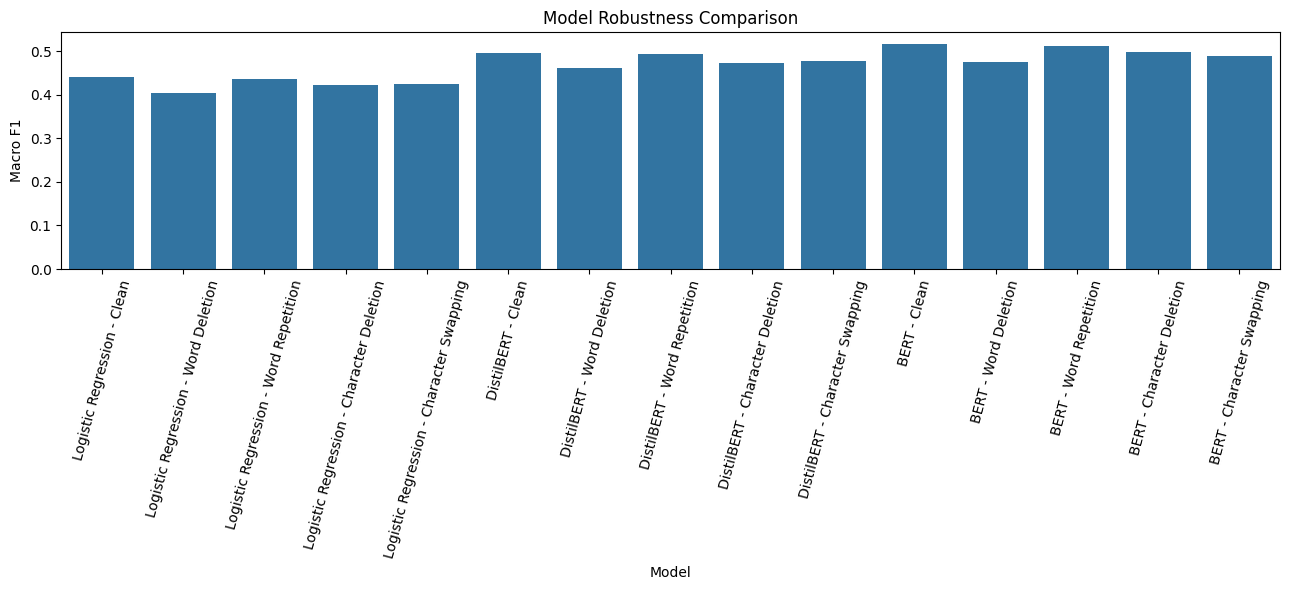

In [77]:
plt.figure(figsize=(13, 6))
sns.barplot(data=all_robustness_results, x="Model", y="Macro F1")
plt.title("Model Robustness Comparison")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [78]:
os.makedirs("research_outputs/robustness", exist_ok=True)
all_robustness_results.to_csv("research_outputs/robustness/robustness_results.csv", index=False)
print("Robustness results saved successfully!")

Robustness results saved successfully!


In [79]:
# EXPECTED CALIBRATION ERROR (ECE) & RELIABILITY DIAGRAM
def calculate_ece(y_true, y_probs, n_bins=10):
    bin_boundaries = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        bin_lower, bin_upper = bin_boundaries[i], bin_boundaries[i + 1]
        in_bin = (y_probs >= bin_lower) & (y_probs < bin_upper)
        prop_in_bin = in_bin.mean()
        if prop_in_bin > 0:
            accuracy_in_bin = y_true[in_bin].mean()
            avg_confidence_in_bin = y_probs[in_bin].mean()
            ece += np.abs(avg_confidence_in_bin - accuracy_in_bin) * prop_in_bin
    return ece

# Calculate ECE for your models
ece_bert = calculate_ece(Y_test, bert_test_scores)
ece_distil = calculate_ece(Y_test, test_scores)
ece_lr = calculate_ece(Y_test, lg_test_scores)

ece_df = pd.DataFrame([
    {"Model": "Logistic Regression", "ECE": ece_lr},
    {"Model": "DistilBERT", "ECE": ece_distil},
    {"Model": "BERT", "ECE": ece_bert}
])

print("Expected Calibration Error (ECE) Comparison:")
display(ece_df.round(4))

Expected Calibration Error (ECE) Comparison:


,Model,ECE
0,Logistic Regression,0.0104
1,DistilBERT,0.0757
2,BERT,0.0733


In [80]:
# EXPLAINABLE AI: FEATURE ATTRIBUTION WITH CAPTUM (INTEGRATED GRADIENTS)

from captum.attr import LayerIntegratedGradients
def predict_forward(inputs, attention_mask=None):
    return bert_model(inputs, attention_mask=attention_mask).logits
lig = LayerIntegratedGradients(predict_forward, bert_model.bert.embeddings)

# Pick an example text from test set
sample_idx = 0
sample_text = X_test.iloc[sample_idx]
sample_true_emotions = [label_names[i] for i, val in enumerate(Y_test[sample_idx]) if val == 1]

inputs = bert_tokenizer(sample_text, return_tensors="pt").to(bert_device)
input_ids = inputs["input_ids"]
attention_mask = inputs["attention_mask"]

with torch.no_grad():
    logits = bert_model(**inputs).logits
    target_class = torch.argmax(logits, dim=1).item()

attributions, delta = lig.attribute(inputs=input_ids, additional_forward_args=(attention_mask,), target=target_class, return_convergence_delta=True)
tokens = bert_tokenizer.convert_ids_to_tokens(input_ids[0])
token_attributions = attributions.sum(dim=-1).squeeze(0).cpu().detach().numpy()
token_attributions = token_attributions / np.linalg.norm(token_attributions)

attr_df = pd.DataFrame({"Token": tokens, "Attribution": token_attributions})
print(f"Text: '{sample_text}'")
print(f"True Emotions: {sample_true_emotions}")
print(f"Predicted Dominant Emotion: {label_names[target_class]}")
display(attr_df.sort_values(by="Attribution", ascending=False).head(8))

Text: 'I’m really sorry about your situation :( Although I love the names Sapphira, Cirilla, and Scarlett!'
True Emotions: ['sadness']
Predicted Dominant Emotion: sadness


,Token,Attribution
5,sorry,0.916656
4,really,0.178021
13,love,0.164429
6,about,0.142699
1,i,0.136664
3,m,0.124406
27,[SEP],0.097251
9,:,0.084735


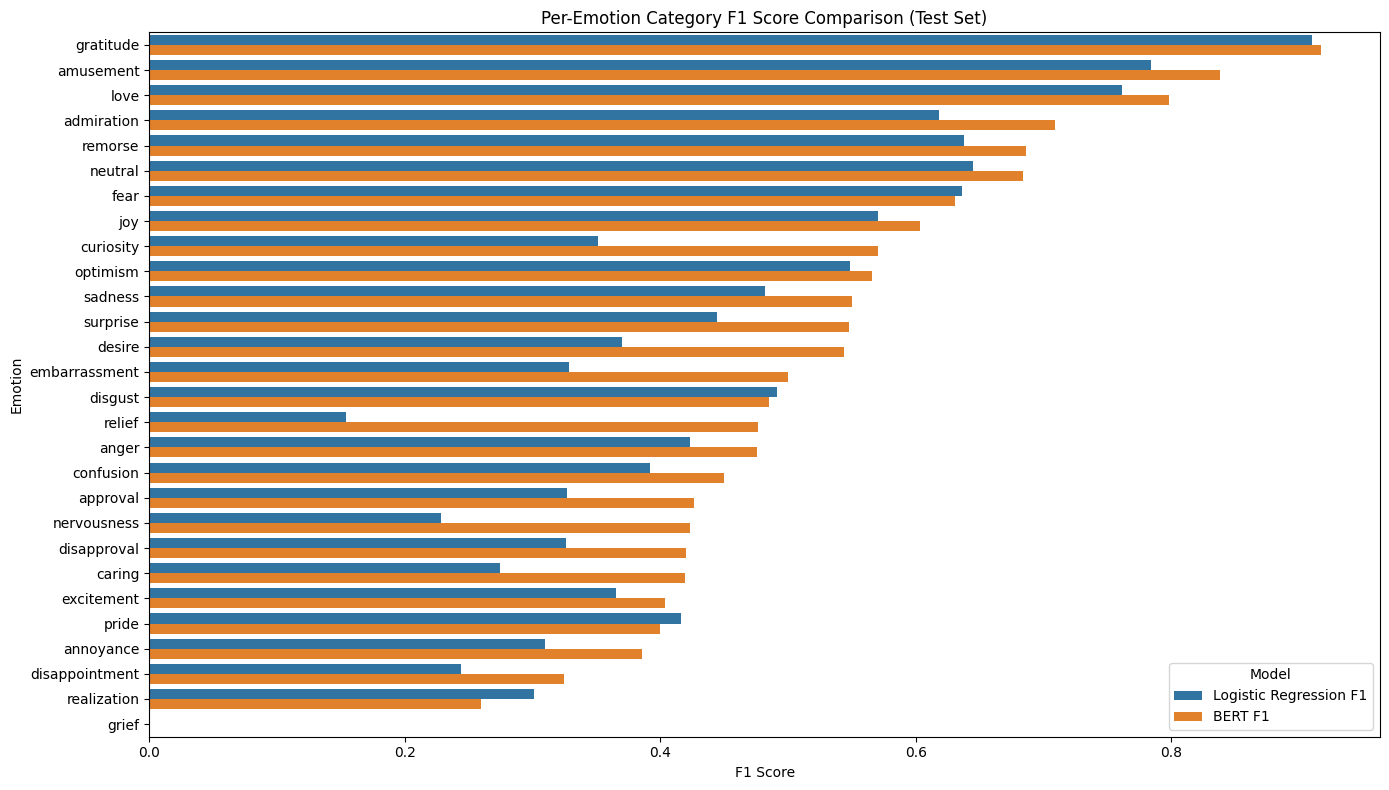

In [81]:
# PER-EMOTION CATEGORY PERFORMANCE BREAKDOWN
f1_per_class_bert = f1_score(Y_test, bert_test_predictions, average=None, zero_division=0)
f1_per_class_lr = f1_score(Y_test, lg_test_pred, average=None, zero_division=0)

per_class_df = pd.DataFrame({"Emotion": label_names, "Logistic Regression F1": f1_per_class_lr, "BERT F1": f1_per_class_bert}).sort_values(by="BERT F1", ascending=False)
plt.figure(figsize=(14, 8))
sns.barplot(data=pd.melt(per_class_df, id_vars="Emotion", var_name="Model", value_name="F1 Score"), x="F1 Score", y="Emotion", hue="Model")
plt.title("Per-Emotion Category F1 Score Comparison (Test Set)")
plt.tight_layout()
plt.show()